# Treino

Regressão linear com a temperatura máxima.


In [1]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

dataset = pd.read_csv("dados/Consumo_cerveja.csv")
X = dataset[["Temperatura Maxima (C)"]].to_numpy()
y = dataset["Consumo de cerveja (litros)"].to_numpy()
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, random_state=0)


b0 7.715
b1 0.660 litros por °C


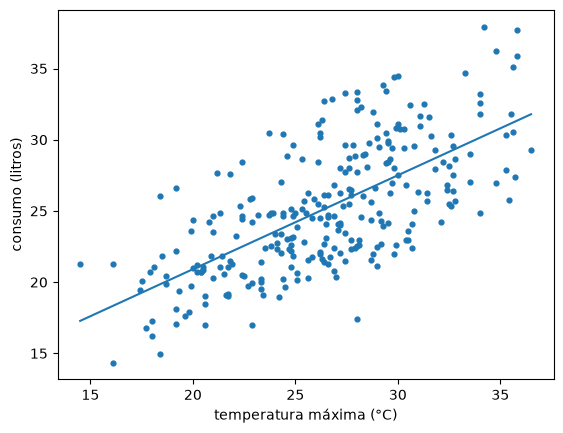

In [2]:
modelo = LinearRegression().fit(X_treino, y_treino)
print(f"b0 {modelo.intercept_:.3f}")
print(f"b1 {modelo.coef_[0]:.3f} litros por °C")

# Pontos: dias do treino. Linha: a reta que acabou de ser calculada.
import matplotlib.pyplot as plt

temperatura = X_treino[:, 0]
ordem = temperatura.argsort()
plt.scatter(temperatura, y_treino, s=12)
plt.plot(temperatura[ordem], modelo.predict(X_treino[ordem]))
plt.xlabel("temperatura máxima (°C)")
plt.ylabel("consumo (litros)")
plt.show()


In [5]:
# Inferência: 30 é a temperatura máxima do dia, em °C.
modelo.predict([[30]])

array([27.5029209])

In [4]:
# MAE: erro médio em litros, sem o sinal. Menor é melhor.
# R²: fração da variação que a previsão acompanha. Maior é melhor.
# Os dois números são desta reta, nos dias que ficaram de fora.
from sklearn.metrics import mean_absolute_error, r2_score

previsto = modelo.predict(X_teste)
print("mae", round(mean_absolute_error(y_teste, previsto), 3))
print("r2", round(r2_score(y_teste, previsto), 3))


mae 2.838
r2 0.262


MAE menor é melhor. R² maior é melhor. Como diminuir esse erro?
